# Unit VI: Data Visualization and Regression

**Syllabus:** 2-D and 3-D visualization; chart legends, bar chart, box plot, histogram, line graph and multiple lines in a line
graph, scatter; core visualisations with Matplotlib and Seaborn; regression: linear regression analysis and multiple linear
regression.

**Part A (6.1-6.8)** is a tour of the standard chart types, each chosen for a question it answers well. **Part B (6.9-6.12)**
fits linear and multiple linear regression to a *numeric* outcome (weekly hours), both **from first principles** (matrix algebra
from Unit IV) and with scikit-learn, and checks the assumptions. The research project itself is classification-only, so this
part is new material on the same data.

In [1]:
import sys, pathlib
for _p in (pathlib.Path.cwd(), pathlib.Path.cwd() / "notebooks"):   # works from notebooks/ or the project root
    if (_p / "common.py").exists():
        sys.path.insert(0, str(_p)); break
from common import *
df = load_adult()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns (UCI Adult, natively-missing rows dropped)")

45,222 rows x 15 columns (UCI Adult, natively-missing rows dropped)


## 6.1 The anatomy of a Matplotlib figure

- **Figure**: the whole canvas. **Axes**: one plot inside it (with its own x/y **axis**, ticks, title, labels, legend).
- Two interfaces: the quick **pyplot** state machine (`plt.plot(...)`) and the explicit **object-oriented** one
  (`fig, ax = plt.subplots(); ax.plot(...)`). Use the object-oriented form whenever there is more than one plot.
- **Seaborn** is a layer on top of Matplotlib that understands DataFrames and statistics (aggregation, confidence intervals,
  grouping by colour); every Seaborn plot is still a Matplotlib figure you can customise.
- A **legend** maps visual encodings (colour, marker, line style) back to meaning: label each artist with `label=...` and call
  `ax.legend()`; place it with `loc=` or outside the plot with `bbox_to_anchor`.

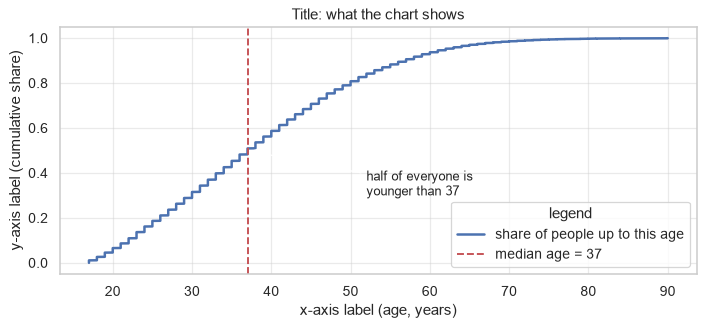

elements to point at: ['Figure', 'Axes', 'XAxis', 'Line2D', 'Legend']


In [2]:
ages = np.sort(df["age"].to_numpy())
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(ages, np.arange(1, len(ages) + 1) / len(ages), color="C0", lw=2, label="share of people up to this age")   # a line artist
ax.axvline(df["age"].median(), color="C3", ls="--", label=f"median age = {df['age'].median():.0f}")                  # a reference line
ax.annotate("half of everyone is\nyounger than 37", xy=(df["age"].median(), 0.5), xytext=(52, 0.3),
            arrowprops=dict(arrowstyle="->"), fontsize=10)                                                          # an annotation
ax.set_title("Title: what the chart shows")                                                                         # title
ax.set_xlabel("x-axis label (age, years)"); ax.set_ylabel("y-axis label (cumulative share)")                        # axis labels
ax.legend(loc="lower right", title="legend")                                                                         # legend
ax.grid(True, alpha=.4)
plt.show()
print("elements to point at:", [type(a).__name__ for a in (fig, ax, ax.xaxis, ax.lines[0], ax.get_legend())])

## 6.2 Bar chart: comparing categories

**Use for:** comparing a number (a count, a share, a mean) across *categories*. Sort the bars (unless the categories have a
natural order), start the axis at zero, label the bars directly. A **grouped** bar compares sub-groups side by side, a
**stacked** bar shows parts of a whole.

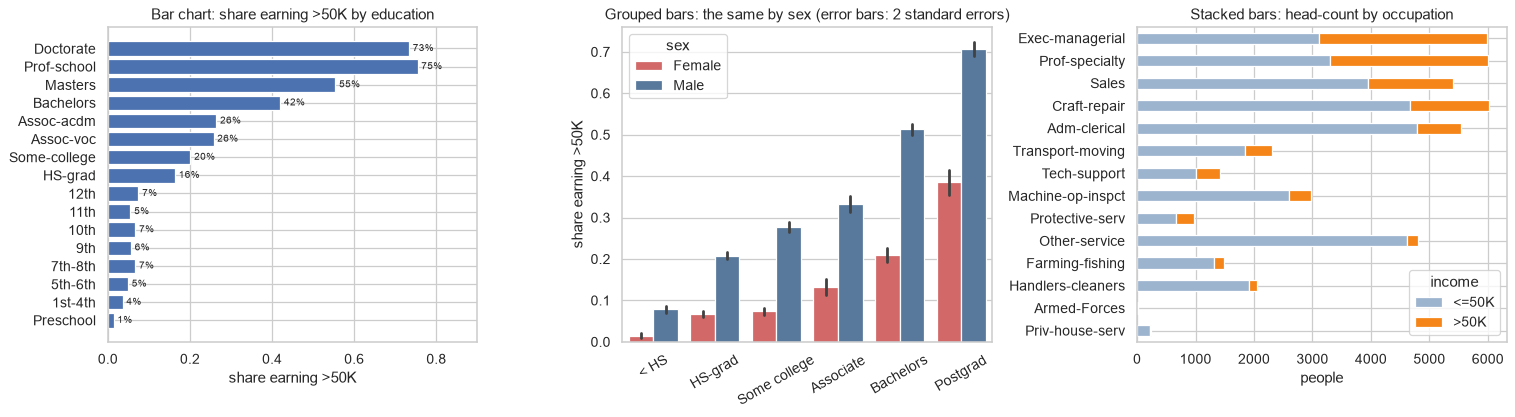

In [3]:
d = df.assign(high=(df[TARGET] == ">50K").astype(int),
              stage=pd.cut(df["education-num"], [0, 8, 9, 10, 12, 13, 16], labels=["< HS", "HS-grad", "Some college", "Associate", "Bachelors", "Postgrad"]))

edu_order = df.groupby("education", observed=True)["education-num"].first().sort_values().index
edu_rate = d.groupby("education", observed=True)["high"].mean().loc[edu_order]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
bars = axes[0].barh(edu_rate.index.astype(str), edu_rate.values, color="C0")                    # ordered categories: keep their natural order
axes[0].bar_label(bars, labels=[f"{v:.0%}" for v in edu_rate.values], padding=3, fontsize=8)
axes[0].set(title="Bar chart: share earning >50K by education", xlabel="share earning >50K", xlim=(0, .9))

sns.barplot(data=d, x="stage", y="high", hue="sex", errorbar=("se", 2), ax=axes[1], palette=["#E45756", "#4C78A8"])
axes[1].set(title="Grouped bars: the same by sex (error bars: 2 standard errors)", xlabel="", ylabel="share earning >50K")
axes[1].tick_params(axis="x", rotation=30); axes[1].legend(title="sex")

ct = pd.crosstab(df["occupation"], df[TARGET]).sort_values(">50K")
ct.plot.barh(stacked=True, ax=axes[2], color=["#9DB4CE", "#F58518"])
axes[2].set(title="Stacked bars: head-count by occupation", xlabel="people", ylabel=""); axes[2].legend(title="income", loc="lower right")
plt.show()

## 6.3 Histogram: the shape of one numeric variable

**Use for:** the distribution of a numeric attribute (centre, spread, skew, gaps, spikes). The only real choice is the **bin
width**: too few bins hide structure, too many show noise. A **KDE** (kernel density estimate) is a smoothed histogram; use
`stat="density"` to compare groups of different size.

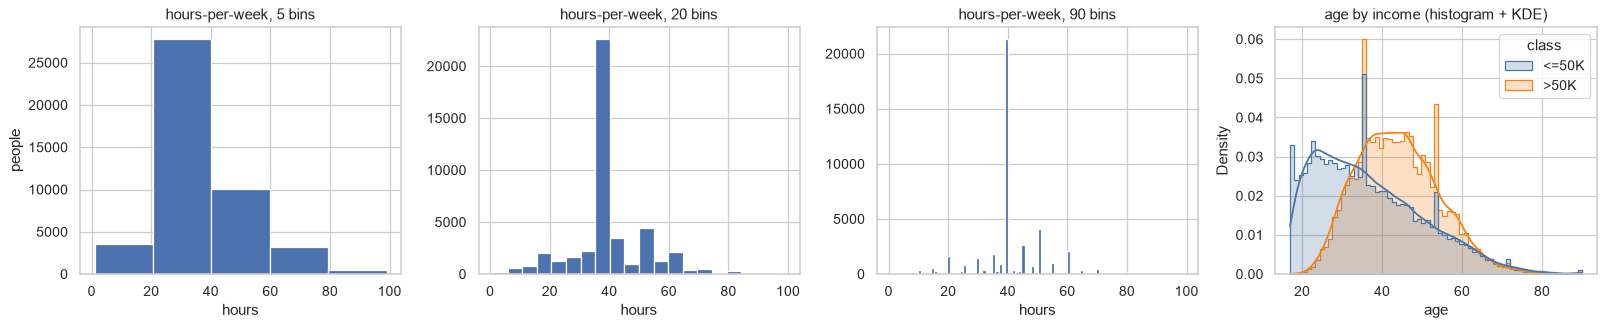

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, b in zip(axes[:3], [5, 20, 90]):
    ax.hist(df["hours-per-week"], bins=b, color="C0"); ax.set(title=f"hours-per-week, {b} bins", xlabel="hours")
axes[0].set_ylabel("people")
sns.histplot(data=df, x="age", hue=TARGET, stat="density", common_norm=False, kde=True, element="step", ax=axes[3], palette=["#4C78A8", "#F58518"])
axes[3].set_title("age by income (histogram + KDE)")
plt.show()

**Bin width changes the story.** With 5 bins the spike at exactly 40 hours disappears into one wide bar; with 90 bins (one per
whole hour) it towers over everything and shows that people report round numbers: 47% of all people say exactly 40 hours, and 20, 50 and 60 are
also spikes. The last panel shows what
histograms are best at: the >50K group has a clearly different, older age distribution.

## 6.4 Box plot: comparing distributions

**Use for:** comparing the distribution of a numeric attribute across *groups*. The box is Q1-median-Q3 (IQR), the whiskers
reach the last point within 1.5 IQR of the box, and dots beyond are *candidate outliers* (Unit III). A **violin plot** adds the
density shape.

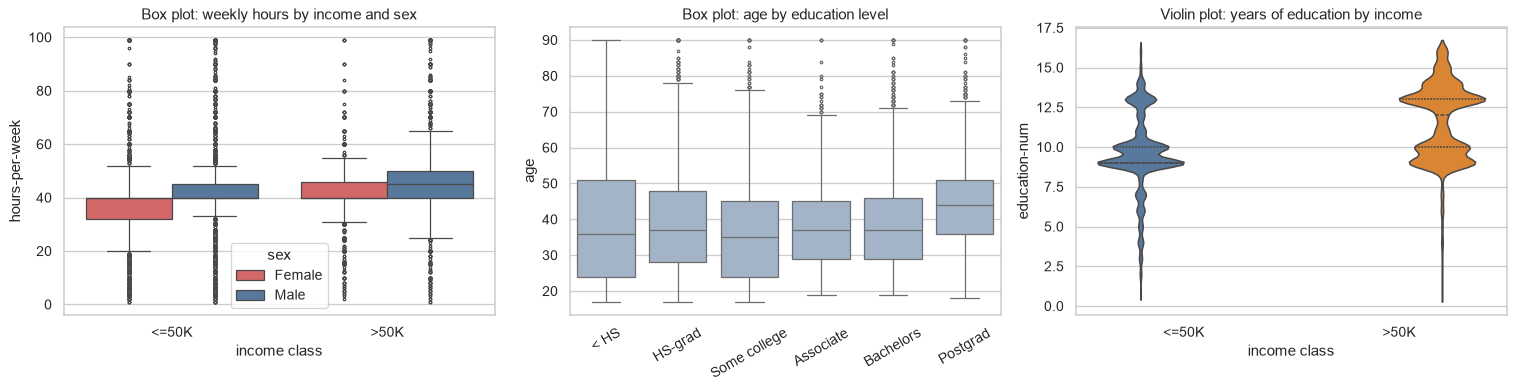

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=d, x=TARGET, y="hours-per-week", hue="sex", ax=axes[0], palette=["#E45756", "#4C78A8"], fliersize=2)
axes[0].set(title="Box plot: weekly hours by income and sex", xlabel="income class")
sns.boxplot(data=d, x="stage", y="age", ax=axes[1], color="#9DB4CE", fliersize=2)
axes[1].set(title="Box plot: age by education level", xlabel=""); axes[1].tick_params(axis="x", rotation=30)
sns.violinplot(data=d, x=TARGET, y="education-num", ax=axes[2], inner="quartile", palette=["#4C78A8", "#F58518"], hue=TARGET, legend=False)
axes[2].set(title="Violin plot: years of education by income", xlabel="income class")
plt.show()

## 6.5 Line graph, and multiple lines in a line graph

**Use for:** how a value changes along an *ordered* axis (time, age, dose). Connect the points only when the x-axis is
ordered and continuous. **Multiple lines** compare groups on the same axes: use distinct colours *and* line styles/markers,
label the lines (legend or direct labels), and keep the number of lines small (about 5 at most).

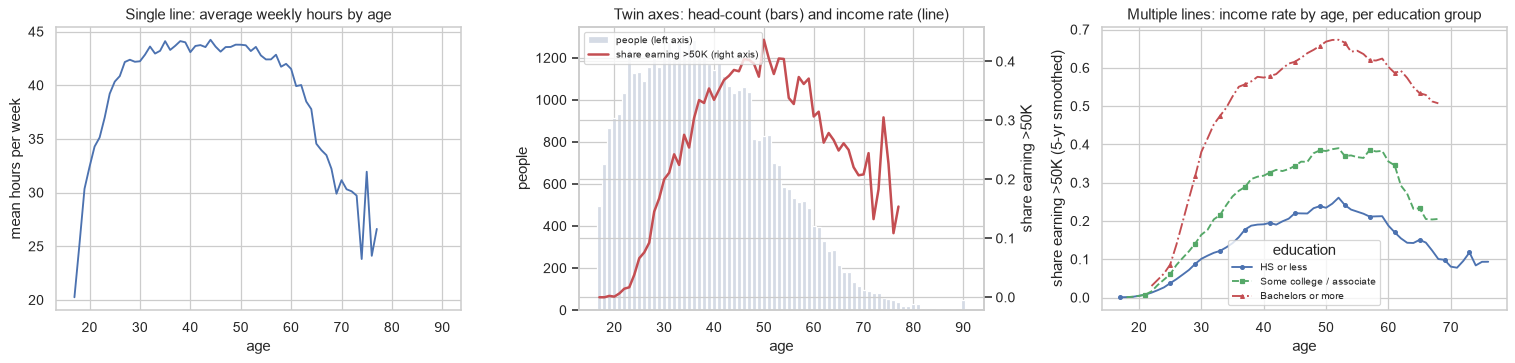

In [6]:
by_age = d.groupby("age").agg(rate=("high", "mean"), people=("high", "size"), hours=("hours-per-week", "mean")).reindex(np.arange(17, 91))
by_age["people"] = by_age["people"].fillna(0)
by_age.loc[by_age["people"] < 30, ["rate", "hours"]] = np.nan                         # too few people to trust: leave a GAP, not a line

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(by_age.index, by_age["hours"], color="C0")
axes[0].set(title="Single line: average weekly hours by age", xlabel="age", ylabel="mean hours per week")

ax2 = axes[1]; ax2b = ax2.twinx()                                                      # two y-axes sharing one x-axis
ax2.bar(by_age.index, by_age["people"], color="#D5DBE5", label="people (left axis)")
ax2b.plot(by_age.index, by_age["rate"], color="C3", lw=2, label="share earning >50K (right axis)")
ax2.set(title="Twin axes: head-count (bars) and income rate (line)", xlabel="age", ylabel="people"); ax2b.set_ylabel("share earning >50K")
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax2b.get_legend_handles_labels()
ax2b.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)                           # one legend for both axes

groups = {"HS or less": d["education-num"] <= 9, "Some college / associate": d["education-num"].between(10, 12), "Bachelors or more": d["education-num"] >= 13}
styles = [("C0", "-", "o"), ("C2", "--", "s"), ("C3", "-.", "^")]
for (name, mask), (color, ls, mk) in zip(groups.items(), styles):
    r = d[mask].groupby("age")["high"].agg(["mean", "size"]).reindex(np.arange(17, 91))
    r.loc[r["size"].fillna(0) < 30, "mean"] = np.nan
    r["smooth"] = r["mean"].rolling(5, center=True, min_periods=3).mean()
    axes[2].plot(r.index, r["smooth"], color=color, ls=ls, marker=mk, ms=3, markevery=4, label=name)
axes[2].set(title="Multiple lines: income rate by age, per education group", xlabel="age", ylabel="share earning >50K (5-yr smoothed)")
axes[2].legend(title="education", fontsize=8)
plt.show()

The multi-line panel shows more than any single line could: *every* group follows the same rise-peak-fall shape over the life
cycle and **peak at the same age (about 52)**, but the **level** differs enormously: the peak rate is about 26% for "HS or
less", 39% for "some college / associate" and 67% for "bachelors or more", and at age 65 the highest group is still above 50%
while the lowest has fallen to about 15%. Education shifts the whole curve *up*; it does not move the peak. (Lines are
smoothed with a 5-year moving average and ages with fewer than 30 people are left as gaps, because tiny groups give jumpy rates and a line drawn across a gap would invent data.)

## 6.6 Scatter plot: the relationship between two numeric variables

**Use for:** seeing whether two numeric attributes move together, and spotting clusters and outliers. With tens of thousands
of points, plain scatter *over-plots* (a solid blob): use transparency (`alpha`), a **sample**, or switch to a density view
(**hexbin**/2-D histogram). Colour, size and marker can encode extra variables.

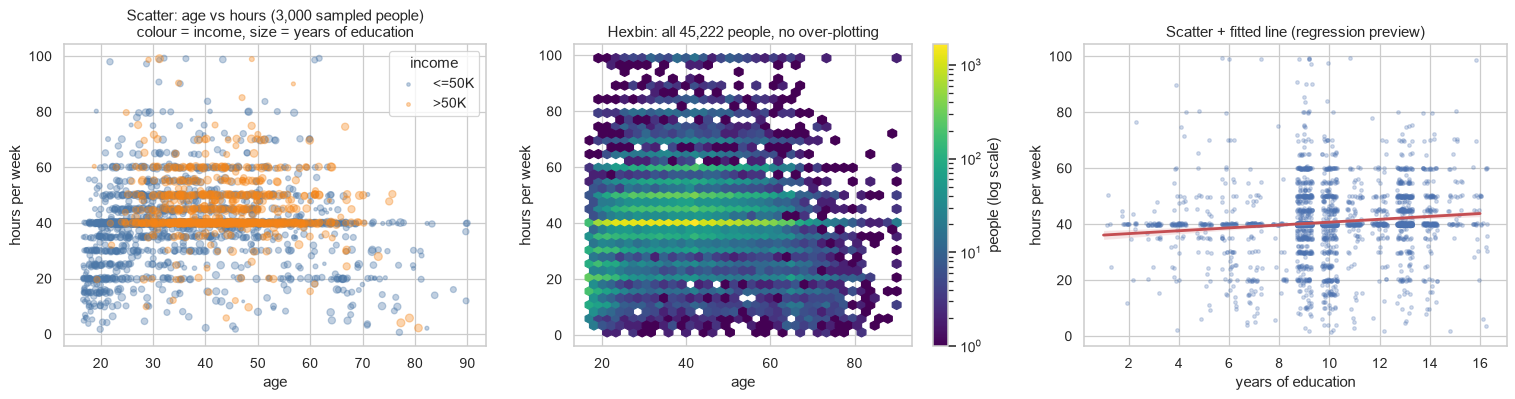

In [7]:
rng = np.random.default_rng(SEED)
s = d.sample(3000, random_state=SEED)
jitter = lambda v, w: v + rng.uniform(-w, w, len(v))                                   # integer data stack on a grid; jitter spreads them

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for cls, col in [("<=50K", "#4C78A8"), (">50K", "#F58518")]:
    m = s[TARGET] == cls
    axes[0].scatter(jitter(s.loc[m, "age"], .4), jitter(s.loc[m, "hours-per-week"], .4), s=s.loc[m, "education-num"] * 2.5, c=col, alpha=.35, label=cls)
axes[0].set(title="Scatter: age vs hours (3,000 sampled people)\ncolour = income, size = years of education", xlabel="age", ylabel="hours per week")
axes[0].legend(title="income", markerscale=.6)

hb = axes[1].hexbin(d["age"], d["hours-per-week"], gridsize=35, cmap="viridis", mincnt=1, bins="log")
fig.colorbar(hb, ax=axes[1], label="people (log scale)"); axes[1].set(title="Hexbin: all 45,222 people, no over-plotting", xlabel="age", ylabel="hours per week")

sns.regplot(data=s, x="education-num", y="hours-per-week", x_jitter=.3, y_jitter=.4, scatter_kws=dict(s=8, alpha=.25), line_kws=dict(color="C3"), ax=axes[2])
axes[2].set(title="Scatter + fitted line (regression preview)", xlabel="years of education", ylabel="hours per week")
plt.show()

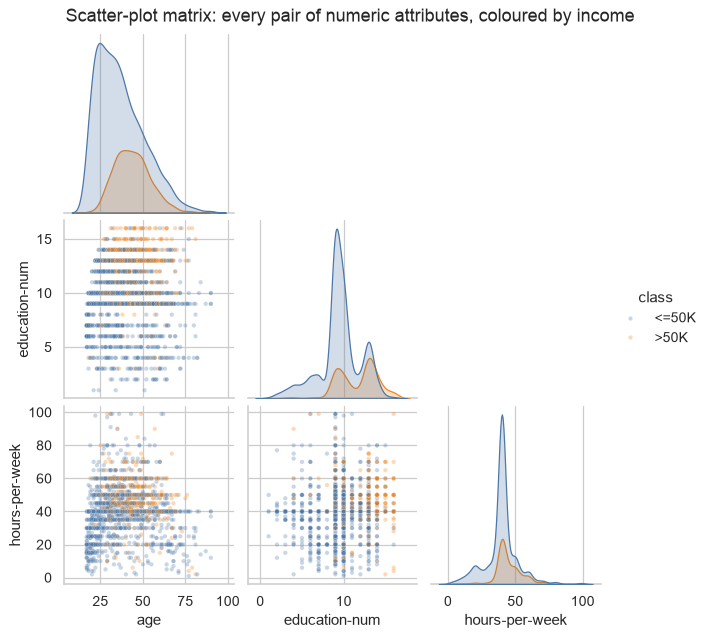

In [8]:
g = sns.pairplot(s[["age", "education-num", "hours-per-week", TARGET]], hue=TARGET, corner=True, diag_kind="kde",
                 plot_kws=dict(alpha=.3, s=12), palette=["#4C78A8", "#F58518"], height=2.3)
g.figure.suptitle("Scatter-plot matrix: every pair of numeric attributes, coloured by income", y=1.02)
plt.show()

## 6.7 Two-dimensional and three-dimensional visualisation

**2-D** summaries of *three* variables: encode the third as colour (heatmap, contour, density). **3-D** adds a third spatial axis:
a **3-D scatter** (three attributes at once), a **surface** (a value over an x-y grid) or **3-D bars**. 3-D charts are
striking but harder to read (perspective hides values), so use them for *exploring shapes*, and prefer a 2-D heatmap or contour for
exact reading. Rotate (`ax.view_init(elev, azim)`) until the pattern is visible.

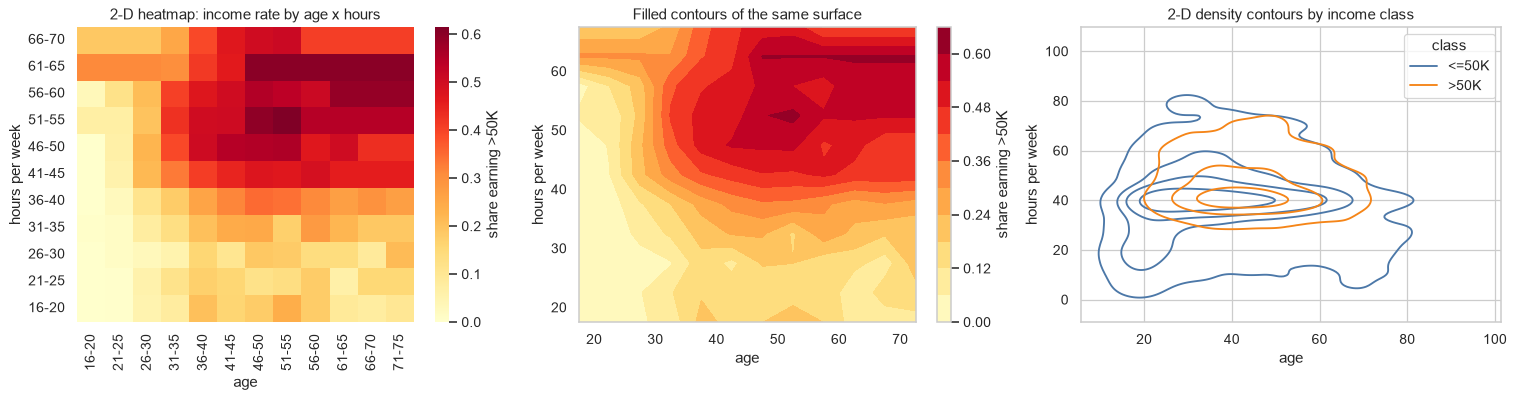

In [9]:
age_bins, hour_bins = np.arange(15, 80, 5), np.arange(15, 75, 5)
tmp = d[(d["age"].between(16, 79)) & (d["hours-per-week"].between(16, 74))]
tmp = tmp.assign(a=pd.cut(tmp["age"], age_bins), h=pd.cut(tmp["hours-per-week"], hour_bins))
cnt = tmp.pivot_table(index="h", columns="a", values="high", aggfunc="size", observed=True)
rate = tmp.pivot_table(index="h", columns="a", values="high", aggfunc="mean", observed=True).where(cnt >= 30)
rate = rate.interpolate(axis=1, limit_direction="both").interpolate(axis=0, limit_direction="both")        # fill the few sparse cells
A_c = np.array([iv.mid for iv in rate.columns]); H_c = np.array([iv.mid for iv in rate.index]); AA, HH = np.meshgrid(A_c, H_c)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
sns.heatmap(rate.iloc[::-1], cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "share earning >50K"},
            xticklabels=[f"{int(iv.left)+1}-{int(iv.right)}" for iv in rate.columns], yticklabels=[f"{int(iv.left)+1}-{int(iv.right)}" for iv in rate.index[::-1]])
axes[0].set(title="2-D heatmap: income rate by age x hours", xlabel="age", ylabel="hours per week")
cs = axes[1].contourf(AA, HH, rate.to_numpy(), levels=10, cmap="YlOrRd"); fig.colorbar(cs, ax=axes[1], label="share earning >50K")
axes[1].set(title="Filled contours of the same surface", xlabel="age", ylabel="hours per week")
sns.kdeplot(data=s, x="age", y="hours-per-week", hue=TARGET, levels=5, ax=axes[2], palette=["#4C78A8", "#F58518"])
axes[2].set(title="2-D density contours by income class", xlabel="age", ylabel="hours per week")
plt.show()

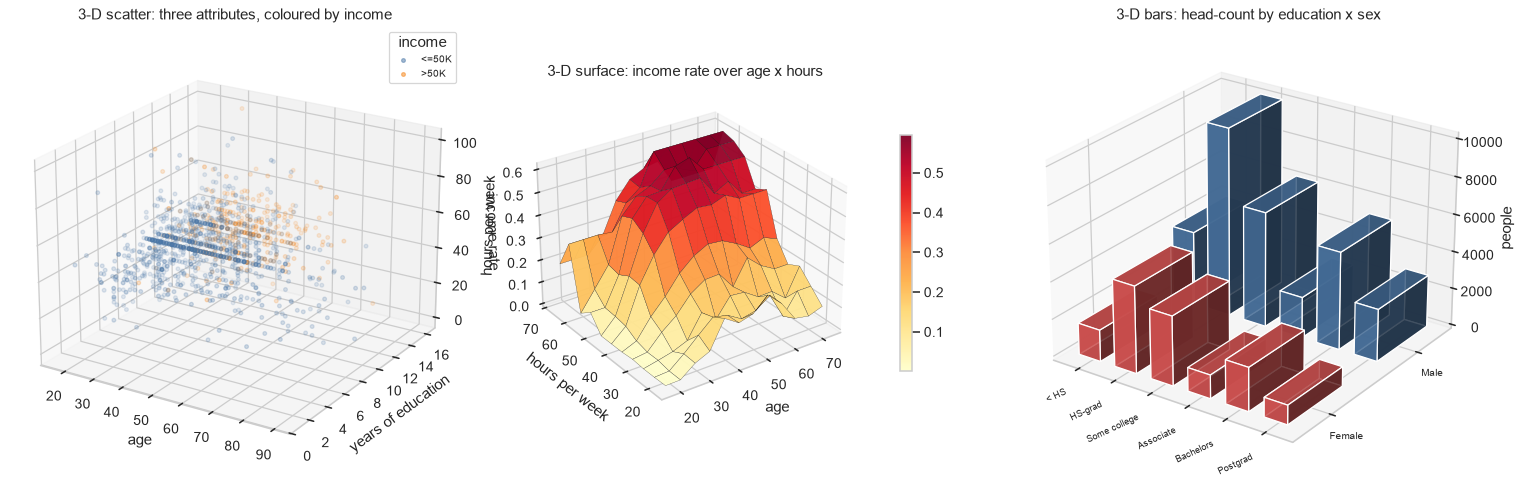

In [10]:
s3 = d.sample(1500, random_state=SEED)
fig = plt.figure(figsize=(17, 5.6))

ax = fig.add_subplot(1, 3, 1, projection="3d")
for cls, col in [("<=50K", "#4C78A8"), (">50K", "#F58518")]:
    m = s3[TARGET] == cls
    ax.scatter(s3.loc[m, "age"], s3.loc[m, "education-num"], s3.loc[m, "hours-per-week"], c=col, s=9, alpha=.5, label=cls)
ax.set(xlabel="age", ylabel="years of education", zlabel="hours per week", title="3-D scatter: three attributes, coloured by income")
ax.view_init(elev=22, azim=-58); ax.legend(title="income", fontsize=8)

ax = fig.add_subplot(1, 3, 2, projection="3d")
surf = ax.plot_surface(AA, HH, rate.to_numpy(), cmap="YlOrRd", edgecolor="k", linewidth=.2, alpha=.95)
ax.set(xlabel="age", ylabel="hours per week", zlabel="income rate", title="3-D surface: income rate over age x hours")
ax.zaxis.labelpad = 2
ax.view_init(elev=28, azim=-125); fig.colorbar(surf, ax=ax, shrink=.5, pad=.1)

ax = fig.add_subplot(1, 3, 3, projection="3d")
bar = d.groupby(["stage", "sex"], observed=True).size().unstack("sex")
xs, ys = np.meshgrid(np.arange(len(bar)), np.arange(bar.shape[1]), indexing="ij")
ax.bar3d(xs.ravel(), ys.ravel(), np.zeros(bar.size), .6, .6, bar.to_numpy().ravel(), color=np.tile(["#E45756", "#4C78A8"], len(bar)), alpha=.85)
ax.set_xticks(np.arange(len(bar)) + .3); ax.set_xticklabels(bar.index, rotation=25, fontsize=7, ha="right")
ax.set_yticks([.3, 1.3]); ax.set_yticklabels(bar.columns, fontsize=8); ax.set_zlabel("people")
ax.set_title("3-D bars: head-count by education x sex"); ax.view_init(elev=25, azim=-55)
plt.show()

In the heatmap/contour/surface views the income rate rises along both axes: the highest cell is ages 51-55 working 51-55 hours
(62% earn >50K) and the lowest is ages 16-20 working 21-25 hours (0%). About 17% of the grid cells hold fewer than 30 people and
are filled by interpolation, so read the surface as a smooth trend, not as exact cell values. The 2-D versions let you read the numbers; the 3-D surface
gives the fastest sense of the shape (a ridge up towards the mid-career, long-hours corner). The 3-D bar chart is the weakest of
the three, since bars in the back are hidden: *a grouped 2-D bar chart (6.2) shows the same thing more clearly*.

## 6.8 Core visualisations with Seaborn: faceting and design choices

**Small multiples** split one chart into a grid of panels (one per level of a categorical variable) that share the same axes, so
the eye compares panels instead of decoding colours. Seaborn offers `FacetGrid`/`displot`; for the bar version below the
panels are drawn explicitly in a loop, so you can see exactly which rows feed each one.

> **A lesson about trusting plots.** The first version of this chart used the figure-level `sns.catplot(kind="bar", col=...)`.
> In this environment (pandas 3.0 with seaborn 0.13.2) its bar heights did **not** match a plain `groupby` (it showed women
> ahead of men by a wide margin, while the data shows them level), so it was replaced by the axes-level `sns.barplot`, which
> matched. The habit worth keeping: *check at least one number on a chart against a `groupby`* (the `check` line below).

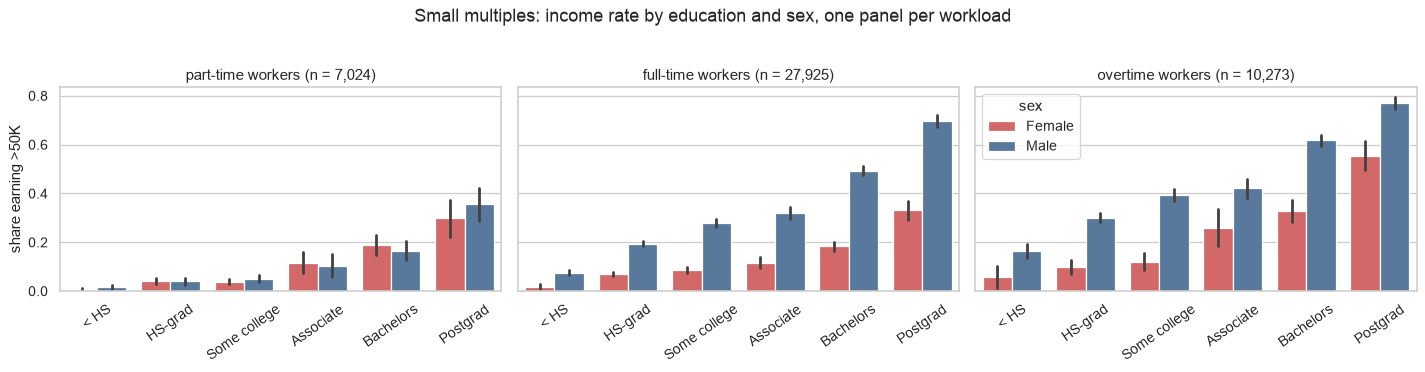

check (part-time, Postgrad): {'Female': 0.298, 'Male': 0.355}


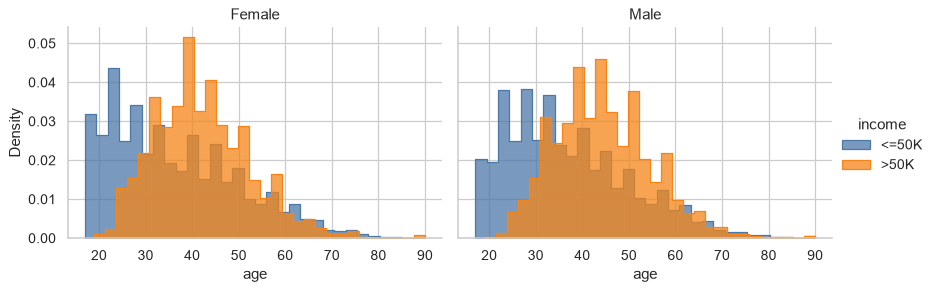

In [11]:
d_w = d.assign(workload=pd.cut(d["hours-per-week"], [0, 34, 45, 100], labels=["part-time", "full-time", "overtime"]))
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, level in zip(axes, d_w["workload"].cat.categories):                              # one panel per workload level
    sub = d_w[d_w["workload"] == level]
    sns.barplot(data=sub, x="stage", y="high", hue="sex", errorbar=("se", 2), ax=ax, palette=["#E45756", "#4C78A8"])
    ax.set(title=f"{level} workers (n = {len(sub):,})", xlabel="", ylabel="share earning >50K" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=35)
    if ax is not axes[-1]:
        ax.get_legend().remove()
fig.suptitle("Small multiples: income rate by education and sex, one panel per workload", y=1.03)
plt.show()

# sanity check: a plot should always agree with a plain groupby
chk = d_w[(d_w["workload"] == "part-time") & (d_w["stage"] == "Postgrad")].groupby("sex", observed=True)["high"].mean().round(3).to_dict()
print("check (part-time, Postgrad):", chk)

fg = sns.FacetGrid(d, col="sex", hue=TARGET, palette=["#4C78A8", "#F58518"], height=3.4, aspect=1.4)
fg.map(sns.histplot, "age", stat="density", common_norm=False, element="step", bins=30).add_legend(title="income")
fg.set_titles("{col_name}")
plt.show()

**Choosing a chart (summary).**

| Question | Chart |
|---|---|
| How is **one numeric** variable distributed? | histogram / KDE / ECDF |
| How do **groups** compare on a numeric variable? | box or violin plot |
| How do **categories** compare on a count or share? | bar chart (grouped / stacked) |
| How does a value **change along an ordered axis**? | line graph (multiple lines for groups) |
| How are **two numeric** variables related? | scatter (hexbin when dense), + fitted line |
| A value over **two numeric** axes? | heatmap / contour (2-D), surface (3-D) |
| Many numeric variables at once? | scatter-plot matrix, correlation heatmap |

**Design rules that matter:** start bar axes at zero; label axes with units; order categories meaningfully; use a
colour-blind-safe palette and do not rely on colour alone (add line styles/markers); avoid pie charts and gratuitous 3-D; show
uncertainty (error bars/CIs) when comparing groups; every chart needs a title that states the *finding or question*.

# Part B: Regression

**Regression** models how a *numeric outcome* `y` depends on one or more *predictors* `x`. **Simple linear regression**:
`y = b0 + b1 x + error`. **Multiple linear regression**: `y = b0 + b1 x1 + b2 x2 + ... + error`. The coefficients are chosen by
**ordinary least squares (OLS)**: minimise the sum of squared residuals, which has the closed-form matrix solution
**`beta = (X'X)^-1 X'y`** (the matrix algebra of Unit IV).

Outcome here: **`hours-per-week`**. Predictors: age, education, capital gain, sex, marital status, income class. We use the
same train/validation/test split as the rest of the project (fit on train, tune on validation, report on test once).

In [12]:
from scipy import stats
from data import three_way_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X, y_cls = df.drop(columns=TARGET), df[TARGET]
X_tr, X_va, X_te, y_tr_cls, y_va_cls, y_te_cls = three_way_split(X, y_cls, seed=SEED)
Y = df["hours-per-week"]
y_tr, y_va, y_te = Y.loc[X_tr.index].to_numpy(float), Y.loc[X_va.index].to_numpy(float), Y.loc[X_te.index].to_numpy(float)
print(f"train {len(X_tr):,} | validation {len(X_va):,} | test {len(X_te):,}; outcome: mean {y_tr.mean():.2f} h, std {y_tr.std():.2f} h")

# strength of each candidate predictor (correlation with the outcome, training data only)
cand = pd.DataFrame({"education-num": X_tr["education-num"], "age": X_tr["age"], "capital-gain": X_tr["capital-gain"],
                     "is_male": (X_tr["sex"] == "Male").astype(int), "is_married": X_tr["marital-status"].astype(str).str.startswith("Married").astype(int),
                     "high_income": (y_tr_cls == ">50K").astype(int)})
corr_y = cand.corrwith(pd.Series(y_tr, index=cand.index)).round(3)
print("correlation with weekly hours:", corr_y.to_dict())

train 31,655 | validation 6,783 | test 6,784; outcome: mean 41.01 h, std 12.02 h
correlation with weekly hours: {'education-num': 0.151, 'age': 0.105, 'capital-gain': 0.081, 'is_male': 0.231, 'is_married': 0.223, 'high_income': 0.228}


## 6.9 Simple linear regression

With a single predictor, the fit is a straight line through the cloud of points. Pick the predictor most correlated with hours
(the table above), fit by the **normal equation** by hand, and compare with scikit-learn. Interpretation: the **slope** is the
average change in `y` for one more unit of `x`; **R-squared** is the share of the variance in `y` explained by the line
(0 = no better than predicting the mean, 1 = perfect); **RMSE** is the typical error in the units of `y`.

Chosen predictor (strongest correlation with hours): education-num
by hand:      hours = 33.851 + 0.707 x education-num
scikit-learn: hours = 33.851 + 0.707 x education-num   (same: True)
validation: R2 = 0.017 | RMSE = 11.90 h vs 12.01 h for always predicting the mean | MAE = 7.45 h


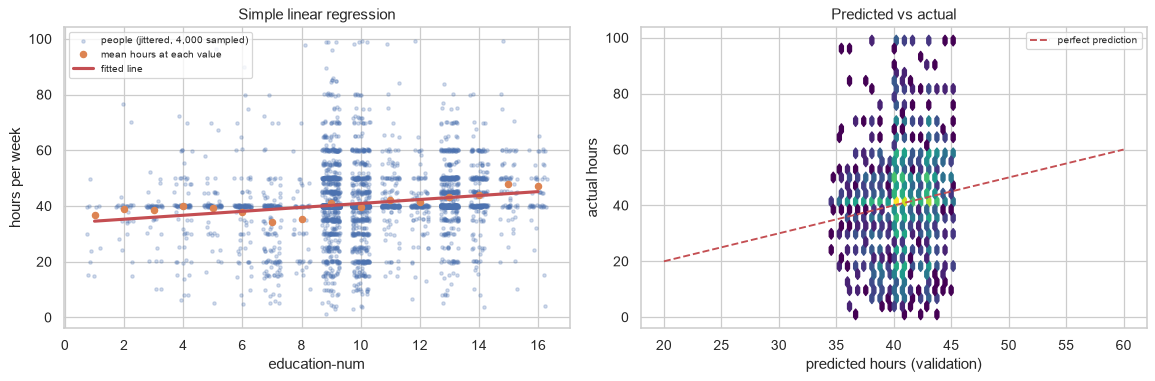

In [13]:
best = corr_y[["education-num", "age", "capital-gain"]].abs().idxmax()            # simple regression needs ONE numeric predictor
x_tr, x_va = X_tr[best].to_numpy(float), X_va[best].to_numpy(float)

D = np.column_stack([np.ones_like(x_tr), x_tr])                       # design matrix: a column of 1s (intercept) and x
beta = np.linalg.solve(D.T @ D, D.T @ y_tr)                           # normal equation (X'X) beta = X'y
sk = LinearRegression().fit(x_tr.reshape(-1, 1), y_tr)
pred_va = beta[0] + beta[1] * x_va
base_rmse = np.sqrt(mean_squared_error(y_va, np.full_like(y_va, y_tr.mean())))
print(f"Chosen predictor (strongest correlation with hours): {best}")
print(f"by hand:      hours = {beta[0]:.3f} + {beta[1]:.3f} x {best}")
print(f"scikit-learn: hours = {sk.intercept_:.3f} + {sk.coef_[0]:.3f} x {best}   (same: {np.allclose(beta, [sk.intercept_, sk.coef_[0]])})")
print(f"validation: R2 = {r2_score(y_va, pred_va):.3f} | RMSE = {np.sqrt(mean_squared_error(y_va, pred_va)):.2f} h "
      f"vs {base_rmse:.2f} h for always predicting the mean | MAE = {mean_absolute_error(y_va, pred_va):.2f} h")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sel = np.random.default_rng(SEED).choice(len(x_tr), 4000, replace=False)
axes[0].scatter(x_tr[sel] + rng.uniform(-.3, .3, len(sel)), y_tr[sel] + rng.uniform(-.4, .4, len(sel)), s=7, alpha=.25, label="people (jittered, 4,000 sampled)")
grp = pd.DataFrame({"x": x_tr, "y": y_tr}).groupby("x")["y"].mean()
axes[0].plot(grp.index, grp.values, "o", color="C1", ms=5, label="mean hours at each value")
xx = np.linspace(x_tr.min(), x_tr.max(), 50); axes[0].plot(xx, beta[0] + beta[1] * xx, "r", lw=2.5, label="fitted line")
axes[0].set(xlabel=best, ylabel="hours per week", title="Simple linear regression"); axes[0].legend(fontsize=8)
axes[1].hexbin(pred_va, y_va, gridsize=30, cmap="viridis", mincnt=1, bins="log"); axes[1].plot([20, 60], [20, 60], "r--", label="perfect prediction")
axes[1].set(xlabel="predicted hours (validation)", ylabel="actual hours", title="Predicted vs actual"); axes[1].legend(fontsize=8)
plt.show()

**Reading it.** The fitted line slopes upward: each extra year of education is associated with about 0.7 more hours (roughly 40
minutes) of work per week. But the **R-squared is small** (the cloud is wide: people with the same education work very different hours),
and the RMSE barely beats "always predict the mean". A real, statistically detectable relationship can still be a *weak
predictor*, which is exactly the difference between *explaining* (inference) and *predicting*. We improve it with more predictors.

## 6.10 Multiple linear regression

Add several predictors at once. Each coefficient is now the effect of that predictor **holding the others fixed**. To judge
significance we need **standard errors**, from the same matrix algebra: `Var(beta) = sigma^2 (X'X)^-1`, then
`t = beta / se` and a p-value from the *t* distribution; overall fit uses **R-squared**, **adjusted R-squared** (penalises
useless predictors) and the **F-test**. We implement it from scratch (about 15 lines) and check it against scikit-learn.

In [14]:
def ols(Xdf, y):
    """Ordinary least squares from first principles (matrix algebra). Returns a coefficient table and fit statistics."""
    Xm = np.column_stack([np.ones(len(Xdf)), Xdf.to_numpy(float)])
    n, k = Xm.shape
    XtX_inv = np.linalg.inv(Xm.T @ Xm)
    beta = XtX_inv @ Xm.T @ y
    resid = y - Xm @ beta
    rss, tss = resid @ resid, ((y - y.mean()) ** 2).sum()
    sigma2 = rss / (n - k)
    se = np.sqrt(np.diag(XtX_inv) * sigma2)
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), n - k)
    half = stats.t.ppf(0.975, n - k) * se
    r2 = 1 - rss / tss
    F = ((tss - rss) / (k - 1)) / (rss / (n - k))
    table = pd.DataFrame({"coef": beta, "std err": se, "t": t, "p-value": p, "CI low": beta - half, "CI high": beta + half}, index=["intercept"] + list(Xdf.columns))
    fit = {"R2": r2, "adj R2": 1 - (1 - r2) * (n - 1) / (n - k), "F": F, "p(F)": stats.f.sf(F, k - 1, n - k), "residual std": np.sqrt(sigma2), "n": n, "k": k}
    return table, fit, beta

AGE_MEAN = X_tr["age"].mean()
def make_design(Xf, cls):
    a = Xf["age"] - AGE_MEAN                                           # centre age so that age and age^2 are less collinear
    return pd.DataFrame({"age (centred)": a, "age (centred) squared": a ** 2, "education-num": Xf["education-num"],
                         "capital-gain (per 1,000)": Xf["capital-gain"] / 1000, "is_male": (Xf["sex"] == "Male").astype(int),
                         "is_married": Xf["marital-status"].astype(str).str.startswith("Married").astype(int), "high_income": (cls == ">50K").astype(int)})

D_tr, D_va, D_te = make_design(X_tr, y_tr_cls), make_design(X_va, y_va_cls), make_design(X_te, y_te_cls)
table, fit, beta_m = ols(D_tr, y_tr)
sk_m = LinearRegression().fit(D_tr, y_tr)
print(f"matches scikit-learn: {np.allclose(beta_m[1:], sk_m.coef_) and np.isclose(beta_m[0], sk_m.intercept_)}")
print(f"R2 = {fit['R2']:.3f} | adjusted R2 = {fit['adj R2']:.3f} | F = {fit['F']:.0f}, {fmt_p(fit['p(F)'])} | residual std = {fit['residual std']:.2f} h | n = {fit['n']:,}")
b1, b2 = table.loc["age (centred)", "coef"], table.loc["age (centred) squared", "coef"]
print(f"The fitted age curve peaks at age {AGE_MEAN - b1 / (2 * b2):.0f}: the slope b1 + 2*b2*(age - mean) reaches zero there.")
table.round(4)

matches scikit-learn: True
R2 = 0.173 | adjusted R2 = 0.173 | F = 945, p < 1e-300 | residual std = 10.94 h | n = 31,655
The fitted age curve peaks at age 44: the slope b1 + 2*b2*(age - mean) reaches zero there.


,coef,std err,t,p-value,CI low,CI high
intercept,36.5227,0.2942,124.1370,0.0,35.9460,37.0993
age (centred),0.1611,0.0055,29.1237,0.0,0.1503,0.1720
age (centred) squared,-0.0151,0.0003,-51.8382,0.0,-0.0156,-0.0145
education-num,0.3202,0.0259,12.3860,0.0,0.2696,0.3709
"capital-gain (per 1,000)",0.0519,0.0084,6.2029,0.0,0.0355,0.0683
is_male,4.3638,0.1460,29.8934,0.0,4.0777,4.6500
is_married,0.7518,0.1550,4.8513,0.0,0.4481,1.0556
high_income,2.1324,0.1734,12.2971,0.0,1.7925,2.4723


**Reading the table.** `coef` is the change in weekly hours for a one-unit increase *with the others held fixed*; `CI low/high`
is the 95% confidence interval; a tiny `p-value` means the coefficient is distinguishable from 0. With 31,000 rows even small
effects are significant, so look at the **size** of `coef` and at the standardised coefficients below, not only at the p-value.
For example, holding the other predictors fixed, men work about 4.4 hours more than women and higher-income people about 2.1 hours
more; being married adds about 0.75 hours; each year of education about 0.3 hours (less than the 0.7 of the simple regression,
because age, sex and marital status now absorb part of that association); and each $1,000 of capital gain adds only 0.05 hours.
The `age (centred) squared` term is **negative**: hours rise with age, then fall (the age curve printed above), something a
straight line in age cannot capture.

,predictors,train R2,train adj R2,validation R2,validation RMSE (h)
education only,1.0,0.0228,0.0227,0.0173,11.9037
+ age (straight line),2.0,0.0327,0.0326,0.0261,11.8505
+ age squared,3.0,0.1260,0.1259,0.1286,11.2095
"+ sex, married, capital gain",6.0,0.1690,0.1688,0.1741,10.9125
+ high income (all 7),7.0,0.1729,0.1727,0.1807,10.8691


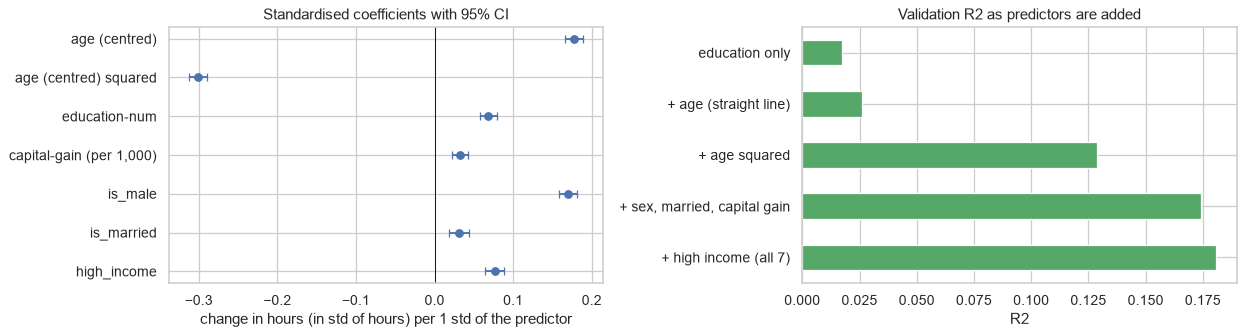

In [15]:
# standardised coefficients: coefficient x (std of predictor / std of outcome) -> comparable across predictors
sd_x, sd_y = D_tr.std().to_numpy(), y_tr.std()
std_coef = table.iloc[1:].copy()
for c in ["coef", "CI low", "CI high"]:
    std_coef[c] = table.iloc[1:][c].to_numpy() * sd_x / sd_y

# incremental model building, judged on the validation set
steps = {"education only": ["education-num"],
         "+ age (straight line)": ["education-num", "age (centred)"],
         "+ age squared": ["education-num", "age (centred)", "age (centred) squared"],
         "+ sex, married, capital gain": ["education-num", "age (centred)", "age (centred) squared", "is_male", "is_married", "capital-gain (per 1,000)"],
         "+ high income (all 7)": list(D_tr.columns)}
rows = {}
for name, cols in steps.items():
    t_, f_, b_ = ols(D_tr[cols], y_tr)
    pv = b_[0] + D_va[cols].to_numpy(float) @ b_[1:]
    rows[name] = {"predictors": len(cols), "train R2": f_["R2"], "train adj R2": f_["adj R2"], "validation R2": r2_score(y_va, pv), "validation RMSE (h)": np.sqrt(mean_squared_error(y_va, pv))}
display(pd.DataFrame(rows).T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
yy = np.arange(len(std_coef))[::-1]
axes[0].errorbar(std_coef["coef"], yy, xerr=[std_coef["coef"] - std_coef["CI low"], std_coef["CI high"] - std_coef["coef"]], fmt="o", capsize=3)
axes[0].axvline(0, color="k", lw=.8); axes[0].set_yticks(yy); axes[0].set_yticklabels(std_coef.index)
axes[0].set(title="Standardised coefficients with 95% CI", xlabel="change in hours (in std of hours) per 1 std of the predictor")
vals = pd.DataFrame({"validation R2": [rows[k]["validation R2"] for k in rows]}, index=list(rows))
vals.plot.barh(ax=axes[1], legend=False, color="C2"); axes[1].invert_yaxis(); axes[1].set(title="Validation R2 as predictors are added", xlabel="R2")
plt.show()

**Model-building reading.** Each step is judged on **validation** data, not just on training R-squared (which can never
decrease when you add a predictor, which is why *adjusted* R-squared and validation R-squared exist). The single
biggest gain is the **age curve** (validation R-squared 0.03 -> 0.13); sex, marital status and capital gain add about 0.045 more,
and income class adds under 0.01. The final model explains only a modest share (about 17-18%) of the variation in weekly hours:
most of what determines how long a person works is *not in these 14 columns*.

## 6.11 Checking the assumptions of linear regression

OLS inference is trustworthy only if (1) the relationship is **linear in the predictors**, (2) residuals have **constant
variance** (homoscedasticity), (3) residuals are roughly **normal** (needed for exact p-values; less important with large n),
(4) observations are **independent**, and (5) predictors are **not highly collinear**. Diagnose with plots of the
**residuals** (actual minus predicted) and with the **variance inflation factor (VIF)**.

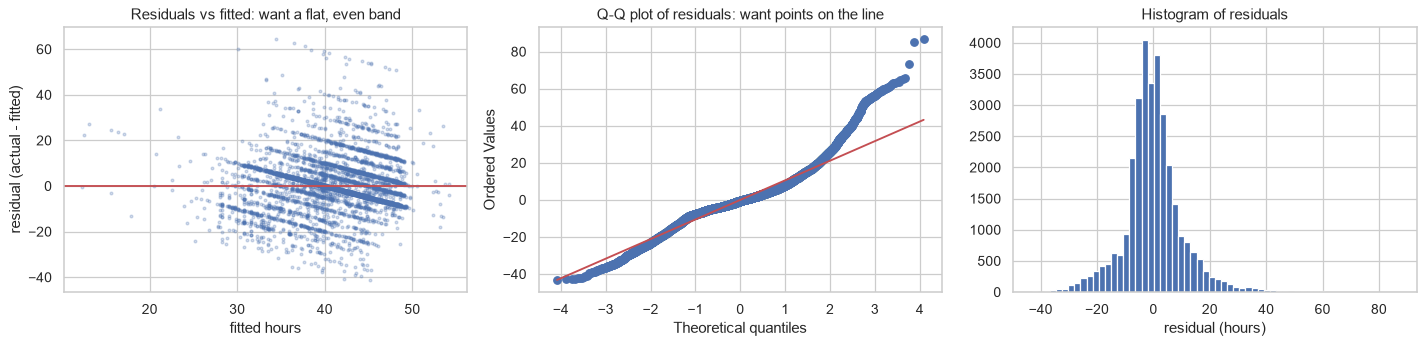

residual mean 0.0000 (always ~0 for OLS with an intercept) | std 10.94 | skewness 0.76 | excess kurtosis 4.14

VIF (>5 is a warning, >10 is serious):


,with raw age and age^2,with centred age (the model above)
age,27.40,1.20
age squared,27.36,1.22
education-num,1.03,1.03


VIF of the final 7 predictors: {'age (centred)': 1.42, 'age (centred) squared': 1.3, 'education-num': 1.16, 'capital-gain (per 1,000)': 1.06, 'is_male': 1.24, 'is_married': 1.59, 'high_income': 1.48}


In [16]:
fitted = beta_m[0] + D_tr.to_numpy(float) @ beta_m[1:]
resid = y_tr - fitted
sel = np.random.default_rng(SEED).choice(len(fitted), 6000, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(fitted[sel], resid[sel] + rng.uniform(-.4, .4, len(sel)), s=5, alpha=.25); axes[0].axhline(0, color="r")
axes[0].set(title="Residuals vs fitted: want a flat, even band", xlabel="fitted hours", ylabel="residual (actual - fitted)")
stats.probplot(resid, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot of residuals: want points on the line")
axes[2].hist(resid, bins=60, color="C0"); axes[2].set(title="Histogram of residuals", xlabel="residual (hours)")
plt.show()
print(f"residual mean {resid.mean():.4f} (always ~0 for OLS with an intercept) | std {resid.std():.2f} | skewness {stats.skew(resid):.2f} | excess kurtosis {stats.kurtosis(resid):.2f}")

def vif(Xdf):
    out = {}
    for c in Xdf.columns:
        others = np.column_stack([np.ones(len(Xdf)), Xdf.drop(columns=c).to_numpy(float)])
        b = np.linalg.lstsq(others, Xdf[c].to_numpy(float), rcond=None)[0]
        r2 = 1 - ((Xdf[c] - others @ b) ** 2).sum() / ((Xdf[c] - Xdf[c].mean()) ** 2).sum()
        out[c] = 1 / (1 - r2)
    return pd.Series(out)

raw_age = pd.DataFrame({"age": X_tr["age"], "age squared": X_tr["age"] ** 2, "education-num": X_tr["education-num"]})
print("\nVIF (>5 is a warning, >10 is serious):")
display(pd.DataFrame({"with raw age and age^2": vif(raw_age).reindex(raw_age.columns), "with centred age (the model above)": vif(D_tr[["age (centred)", "age (centred) squared", "education-num"]]).rename(lambda c: c.replace(" (centred)", ""))}).round(2))
print("VIF of the final 7 predictors:", vif(D_tr).round(2).to_dict())

**What the diagnostics say.**
- *Residuals vs fitted:* the band is not flat. There is a visible slanted edge, because `hours-per-week` cannot go below 1 or
  above 99 and is **piled up at exactly 40**: the outcome is *bounded and spiky*, so the residuals are skewed and have heavy tails
  (see skewness/kurtosis). The Q-Q plot bends away from the line at both ends. This does not make the coefficients *wrong*
  (OLS is still the best linear fit), but standard errors and p-values are only approximate, and **predictions should not be
  trusted for individuals**. A different model (or a transformed outcome) would fit better.
- *Multicollinearity:* raw `age` and `age squared` are almost the same variable (huge VIF); **centring age before squaring**
  removes the artificial correlation (low VIF), which is why the model above centred it. All final predictors are fine.

## 6.12 Final test result, and why regression is the wrong tool for a yes/no outcome

The model is fixed (it was chosen on validation data), so we now report the **test set exactly once**:

In [17]:
pred_te = beta_m[0] + D_te.to_numpy(float) @ beta_m[1:]
print(f"TEST (used once): R2 = {r2_score(y_te, pred_te):.3f} | RMSE = {np.sqrt(mean_squared_error(y_te, pred_te)):.2f} h "
      f"| MAE = {mean_absolute_error(y_te, pred_te):.2f} h  (always predicting the training mean: RMSE {np.sqrt(mean_squared_error(y_te, np.full_like(y_te, y_tr.mean()))):.2f} h)")

# What if we (wrongly) use linear regression for the 0/1 income outcome?
y01_tr = (y_tr_cls == ">50K").astype(float).to_numpy()
Xc = pd.DataFrame({"age": X_tr["age"], "education-num": X_tr["education-num"], "hours": X_tr["hours-per-week"], "is_male": (X_tr["sex"] == "Male").astype(int),
                   "is_married": X_tr["marital-status"].astype(str).str.startswith("Married").astype(int), "capital-gain (k)": X_tr["capital-gain"] / 1000})
lpm = LinearRegression().fit(Xc, y01_tr)
p01 = lpm.predict(Xc)
print(f"\nLinear regression on the 0/1 income outcome: {np.mean((p01 < 0) | (p01 > 1)):.1%} of the 'probabilities' fall outside [0, 1] "
      f"(range {p01.min():.2f} to {p01.max():.2f}).")

TEST (used once): R2 = 0.170 | RMSE = 10.86 h | MAE = 7.47 h  (always predicting the training mean: RMSE 11.93 h)

Linear regression on the 0/1 income outcome: 15.5% of the 'probabilities' fall outside [0, 1] (range -0.48 to 1.64).


A linear model on a 0/1 target happily predicts "probabilities" below 0 or above 1 and has non-constant residual variance by
construction. For **categorical outcomes use classification**: **logistic regression** (Unit I, 1.5) models the *log-odds*
as a linear function of the predictors and always returns a valid probability. That is why the research project is
a *classification* project, and why regression appears here only for a genuinely numeric outcome.

### Regression take-aways
1. OLS = minimise squared residuals = `beta = (X'X)^-1 X'y`; the library and the algebra give identical answers.
2. Read **coefficients with their uncertainty** (CI), compare predictors on a **standardised** scale, and judge fit on
   **validation/test data** (adjusted R-squared on training data is only a guide).
3. Check the **assumptions** with residual plots and VIF; here the bounded, spiky outcome shows up clearly.
4. A significant relationship is not necessarily a strong predictor: report effect size and R-squared, not only the p-value.